# Sales Data Quality, Insights & CSV Operations
## Part A — Data Quality & Basic Insights (70 marks)
This notebook uses relative paths and preserves `sales_raw.csv`. Run all cells in order.
Dates use month/day/year. Revenue is in unspecified currency units; the source does not identify a currency.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

raw = pd.read_csv('sales_raw.csv')
print('First five rows:')
display(raw.head())
print('Shape:', raw.shape)
print('Columns:', raw.columns.tolist())
print('Data types:')
print(raw.dtypes)
print('Missing values:')
print(raw.isna().sum())
print('Duplicate rows:', raw.duplicated().sum())

First five rows:


,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,10/1/2026,North,food,2.0,120
1,1002,10/1/2026,South,Books,1.0,250
2,1003,10/2/2026,North,Food,3.0,110
3,1004,10/2/2026,East,Stationery,4.0,50
4,1005,10/3/2026,SOUTH,books,2.0,250


Shape: (21, 6)
Columns: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']
Data types:
transaction_id      int64
sale_date             str
region                str
category              str
quantity          float64
unit_price            str
dtype: object
Missing values:
transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64
Duplicate rows: 1


### Cleaning rules
* Strip whitespace and use title case for region and category. Fill an absent region with `Unknown` to retain otherwise usable sales without inventing a location.
* Remove exact duplicate rows, keeping the first occurrence.
* Convert dates and numeric values explicitly; invalid values become missing. Drop rows with missing/invalid dates, quantity, or price, and nonpositive quantity or price. This avoids inventing amounts or assuming that a negative quantity is a return.
* Retain the price of 10,000: it is unusual, but the source provides no correction or valid upper limit. Flag it separately and disclose its influence on the findings. An outlier is not automatically an error.
* No missing category occurs in this file; a missing category would be labelled `Unknown`.

In [2]:
clean = raw.copy()
before = len(clean)
clean = clean.drop_duplicates().copy()
duplicates_removed = before - len(clean)
for column in ['region', 'category']:
    clean[column] = clean[column].astype('string').str.strip().str.title()
    clean[column] = clean[column].replace('', pd.NA).fillna('Unknown')
clean['sale_date'] = pd.to_datetime(clean['sale_date'], format='%m/%d/%Y', errors='coerce')
for column in ['quantity', 'unit_price']:
    clean[column] = pd.to_numeric(clean[column], errors='coerce')

invalid = (clean[['sale_date', 'quantity', 'unit_price']].isna().any(axis=1)
           | clean['quantity'].le(0) | clean['unit_price'].le(0))
print('Rejected transactions after duplicate removal:')
display(clean.loc[invalid])
rejected_count = int(invalid.sum())
clean = clean.loc[~invalid].reset_index(drop=True)
clean['quantity'] = clean['quantity'].astype(int)
clean['revenue'] = (clean['quantity'] * clean['unit_price']).round(2)
print(f'Rows before: {before}; duplicates removed: {duplicates_removed}; '
      f'invalid/incomplete rows removed: {rejected_count}; rows after: {len(clean)}')
print('Remaining missing values:')
print(clean.isna().sum())
display(clean)

Rejected transactions after duplicate removal:


,transaction_id,sale_date,region,category,quantity,unit_price
5,1006,2026-10-03,West,Food,NaN,130.0
9,1010,2026-10-05,South,Stationery,2.0,NaN
10,1011,2026-10-06,East,Food,2.0,NaN
12,1013,2026-10-07,South,Food,-2.0,130.0
13,1014,NaT,West,Books,2.0,300.0


Rows before: 21; duplicates removed: 1; invalid/incomplete rows removed: 5; rows after: 15
Remaining missing values:
transaction_id    0
sale_date         0
region            0
category          0
quantity          0
unit_price        0
revenue           0
dtype: int64


,transaction_id,sale_date,region,category,quantity,unit_price,revenue
0,1001,2026-10-01,North,Food,2,120.0,240.0
1,1002,2026-10-01,South,Books,1,250.0,250.0
2,1003,2026-10-02,North,Food,3,110.0,330.0
3,1004,2026-10-02,East,Stationery,4,50.0,200.0
4,1005,2026-10-03,South,Books,2,250.0,500.0
5,1007,2026-10-04,North,Stationery,3,60.0,180.0
6,1008,2026-10-04,East,Books,1,300.0,300.0
7,1009,2026-10-05,West,Food,5,90.0,450.0
8,1012,2026-10-06,North,Books,1,320.0,320.0
9,1015,2026-10-08,East,Food,2,120.0,240.0


In [3]:
region_summary = (clean.groupby('region', as_index=False)
                  .agg(total_revenue=('revenue', 'sum'), transactions=('transaction_id', 'count'))
                  .sort_values('total_revenue', ascending=False))
category_summary = (clean.groupby('category', as_index=False)['revenue'].sum()
                    .sort_values('revenue', ascending=False))
print('Revenue by region:')
display(region_summary)
print('Revenue by category:')
display(category_summary)
region_summary.to_csv('revenue_by_region.csv', index=False)
category_summary.to_csv('revenue_by_category.csv', index=False)
print('Total revenue:', f"{clean['revenue'].sum():,.2f}")

Revenue by region:


,region,total_revenue,transactions
1,North,11470.0,6
2,South,1035.0,3
0,East,740.0,3
4,West,530.0,2
3,Unknown,400.0,1


Revenue by category:


,category,revenue
2,Stationery,10460.0
1,Food,1945.0
0,Books,1770.0


Total revenue: 14,175.00


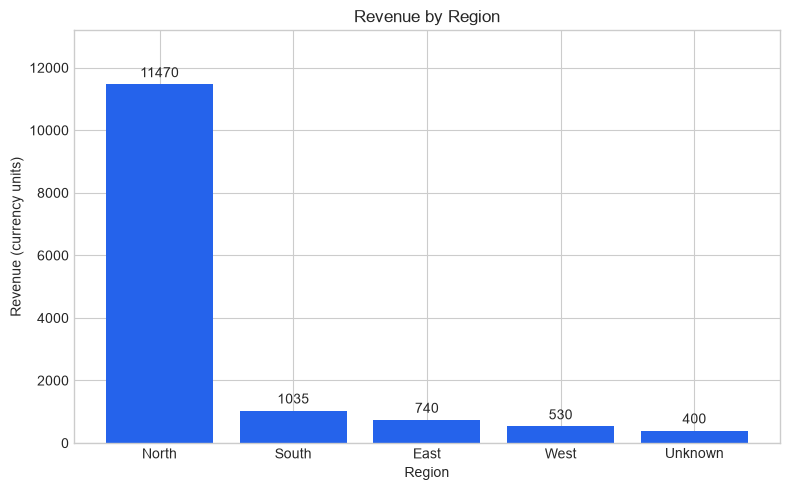

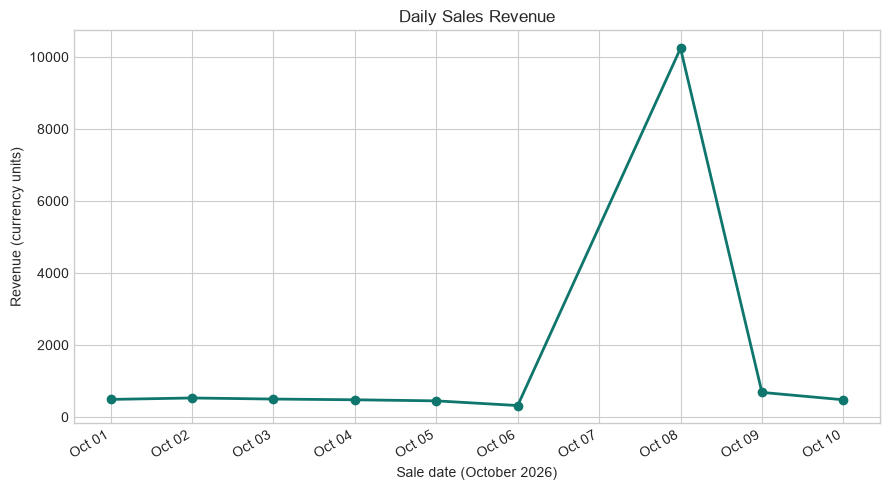

In [4]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(region_summary['region'], region_summary['total_revenue'], color='#2563eb')
ax.bar_label(bars, fmt='%.0f', padding=3)
ax.set(title='Revenue by Region', xlabel='Region', ylabel='Revenue (currency units)')
ax.set_ylim(0, region_summary['total_revenue'].max() * 1.15)
fig.tight_layout()
fig.savefig('revenue_by_region.png', dpi=160)
plt.show()

daily = clean.groupby('sale_date')['revenue'].sum().sort_index()
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(daily.index, daily.values, marker='o', color='#0f766e', linewidth=2)
ax.set(title='Daily Sales Revenue', xlabel='Sale date (October 2026)', ylabel='Revenue (currency units)')
import matplotlib.dates as mdates
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig('daily_revenue.png', dpi=160)
plt.show()

In [5]:
total = clean['revenue'].sum()
leader = region_summary.iloc[0]
unusual = clean.loc[clean['unit_price'].eq(10000)].iloc[0]
peak_date = daily.idxmax()
findings = (
    f"1. {leader['region']} leads regional revenue with {leader['total_revenue']:,.2f} "
    f"({leader['total_revenue'] / total:.1%} of the {total:,.2f} total). "
    f"Transaction {int(unusual['transaction_id'])} alone contributes {unusual['revenue']:,.2f} "
    f"({unusual['revenue'] / total:.1%} of total), so this lead depends heavily on an unverified high price.\n\n"
    f"2. Daily revenue peaks on {peak_date:%Y-%m-%d} at {daily.max():,.2f}. "
    f"Excluding that high-price transaction would reduce that day's revenue to "
    f"{daily.loc[unusual['sale_date']] - unusual['revenue']:,.2f}; "
    "the peak should not be interpreted as a sustained sales trend."
)
print(findings)
Path('findings.md').write_text('# Two evidence-based findings\n\n' + findings + '\n', encoding='utf-8')
clean.to_csv('cleaned_sales.csv', index=False, date_format='%Y-%m-%d')
print('Saved cleaned_sales.csv')

1. North leads regional revenue with 11,470.00 (80.9% of the 14,175.00 total). Transaction 1016 alone contributes 10,000.00 (70.5% of total), so this lead depends heavily on an unverified high price.

2. Daily revenue peaks on 2026-10-08 at 10,240.00. Excluding that high-price transaction would reduce that day's revenue to 240.00; the peak should not be interpreted as a sustained sales trend.
Saved cleaned_sales.csv


## Part B — CSV File Handling & Manipulation (30 marks)
Reload Part A's output. Calculate tax at 5% of revenue. Apply the Books price increase, then recompute all dependent amounts. Remove transaction **1002** as a deliberate row-deletion demonstration; this does not imply it was invalid. Create and drop a temporary review column.

In [6]:
updated = pd.read_csv('cleaned_sales.csv')
updated['tax_amount'] = (updated['revenue'] * 0.05).round(2)
print('First five rows after adding tax:')
display(updated.head())

books = updated['category'].eq('Books')
updated.loc[books, 'unit_price'] = (updated.loc[books, 'unit_price'] * 1.10).round(2)
updated['revenue'] = (updated['quantity'] * updated['unit_price']).round(2)
updated['tax_amount'] = (updated['revenue'] * 0.05).round(2)
print('Books after the 10% price increase:')
display(updated.loc[books])

selected_id = 1002
assert updated['transaction_id'].eq(selected_id).sum() == 1
updated = updated.drop(index=updated.index[updated['transaction_id'].eq(selected_id)])
updated['review_status'] = 'Reviewed'
print('Temporary columns:', updated.columns.tolist())
updated = updated.drop(columns=['review_status']).reset_index(drop=True)
updated.to_csv('sales_updated.csv', index=False)

verified = pd.read_csv('sales_updated.csv')
print('Saved file, first five rows:')
display(verified.head())
print('Final column names:', verified.columns.tolist())
print('Final shape:', verified.shape)

First five rows after adding tax:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2,120.0,240.0,12.0
1,1002,2026-10-01,South,Books,1,250.0,250.0,12.5
2,1003,2026-10-02,North,Food,3,110.0,330.0,16.5
3,1004,2026-10-02,East,Stationery,4,50.0,200.0,10.0
4,1005,2026-10-03,South,Books,2,250.0,500.0,25.0


Books after the 10% price increase:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
1,1002,2026-10-01,South,Books,1,275.0,275.0,13.75
4,1005,2026-10-03,South,Books,2,275.0,550.0,27.50
6,1008,2026-10-04,East,Books,1,330.0,330.0,16.50
8,1012,2026-10-06,North,Books,1,352.0,352.0,17.60
12,1018,2026-10-09,Unknown,Books,2,220.0,440.0,22.00


Temporary columns: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount', 'review_status']
Saved file, first five rows:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2,120.0,240.0,12.0
1,1003,2026-10-02,North,Food,3,110.0,330.0,16.5
2,1004,2026-10-02,East,Stationery,4,50.0,200.0,10.0
3,1005,2026-10-03,South,Books,2,275.0,550.0,27.5
4,1007,2026-10-04,North,Stationery,3,60.0,180.0,9.0


Final column names: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']
Final shape: (14, 8)


In [7]:
# Verify the saved results and the requested manipulations.
pd.testing.assert_frame_equal(verified, updated)
assert len(clean) == before - duplicates_removed - rejected_count
assert not clean.isna().any().any() and not clean.duplicated().any()
assert not clean['transaction_id'].duplicated().any()
assert len(verified) == len(clean) - 1
assert selected_id not in verified['transaction_id'].values
assert 'review_status' not in verified.columns
pd.testing.assert_series_equal(verified['revenue'],
    (verified['quantity'] * verified['unit_price']).round(2), check_names=False)
pd.testing.assert_series_equal(verified['tax_amount'],
    (verified['revenue'] * 0.05).round(2), check_names=False)
original_books = clean.set_index('transaction_id').loc[
    verified.loc[verified['category'].eq('Books'), 'transaction_id'], 'unit_price']
assert (verified.loc[verified['category'].eq('Books'), 'unit_price'].to_numpy()
        == (original_books * 1.10).round(2).to_numpy()).all()
print('All output and manipulation checks passed.')

All output and manipulation checks passed.
